# Base sales from total sales: a UCM, a smoothed level or no base at all

**Audience:** analysts who have read guide 01 and have total sales, not a base sales series.

**What this notebook does:** the VECM explains slow movements in sales through the brand metrics. Short-term effects (performance media, promotions, seasonality) are not part of that story, so the usual first step is to take them out and give the VECM **base sales**. This notebook asks which way of doing that gives the right answer, on data where the true base is known.

Four ways in, all with a `statsmodels` unobserved components model (UCM) except the last:

- **Total minus contributions:** total sales minus the UCM's regression contributions and its seasonal component. The noise stays in.
- **Total minus contributions, seasonal kept:** the same, but the seasonality stays in the base and the VECM models it.
- **The smoothed level:** the UCM's level component. Cain (2022) passes this to his long-run model.
- **No base:** log total sales straight into the VECM, with the short-term drivers in the sales equation.

Every short-term effect in the simulated data is linear and lands in the same week, so the UCM is correctly specified. Carryover and saturation in the short-term part need a Bayesian MMM, which is a later guide.

In [1]:
# Sampling configuration, as in the other guides.
FAST_SAMPLING = True

if FAST_SAMPLING:
    DRAWS, TUNE, CHAINS = 1000, 1000, 2
else:
    DRAWS, TUNE, CHAINS = 2000, 1000, 4

LEVEL = 0.90  # every interval in this notebook is a 90% interval
TAILS = (100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2)

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.structural import UnobservedComponents

from bayesian_vecm import BayesianVECM, simulate_brand_data

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)
COLOURS = {
    "true_base": "black",
    "ucm_minus": "#2a78d6",
    "ucm_level": "#eb6834",
    "ucm_keep_season": "#8a5cc2",
    "total": "#3a9e5f",
}
LABELS = {
    "true_base": "true base",
    "ucm_minus": "UCM: total minus contributions",
    "ucm_level": "UCM: smoothed level",
    "ucm_keep_season": "UCM: minus contributions, seasonal kept",
    "total": "total sales, no base",
}
SPEC = {"k_ar_diff": 1, "coint_rank": 2, "deterministic": "co"}
SALES, AWARE, CONS = "organic_sales", "brand_awareness", "brand_consideration"
SHORT_TERM = ["brand_spend", "paid_search", "paid_social", "promo"]
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

## 1. The data

`simulate_brand_data(total_sales=True)` keeps the brand system of the other guides and adds the series an analyst actually sees: weekly sales in £, built as

- the **base**, `exp(organic_sales)`, the part the brand metrics explain;
- a **same-week hit from brand spend**, on top of its slow effect through awareness and consideration;
- **paid search** and **paid social**, which move sales for a week and never touch the brand metrics;
- a **promotion** flag on about 8% of weeks;
- **annual seasonality**;
- **weekly noise** that is not part of the brand system: one-off events, stock-outs, measurement error. Here its standard deviation is 2% of the reference level.

The parts add up exactly to total sales. One unit of brand spend is £1,000, as in guide 01.

In [3]:
NOISE = 0.02  # weekly noise outside the brand system, share of the reference level
COST_GBP = 1_000.0  # one unit of brand spend

data = simulate_brand_data(total_sales=True, sales_noise=NOISE)
endog, exog, truth = data.endog, data.exog, data.truth
total = data.sales["total_sales"]
parts = truth.sales_parts
short_term = pd.concat([exog[["brand_spend"]], data.sales_drivers], axis=1)[SHORT_TERM]

summary = pd.DataFrame(
    {
        "average £ a week": parts.mean(),
        "sd £ a week": parts.std(),
        "share of total sales": parts.mean() / total.mean(),
    }
)
summary.loc["total sales"] = [total.mean(), total.std(), 1.0]
summary.round({"average £ a week": 0, "sd £ a week": 0, "share of total sales": 3})

,average £ a week,sd £ a week,share of total sales
base,1465.0,336.0,0.883
brand_spend,0.0,25.0,0.000
paid_search,114.0,45.0,0.068
paid_social,72.0,30.0,0.044
promo,9.0,36.0,0.006
seasonality,0.0,76.0,0.000
noise,-2.0,32.0,-0.001
total sales,1659.0,348.0,1.000


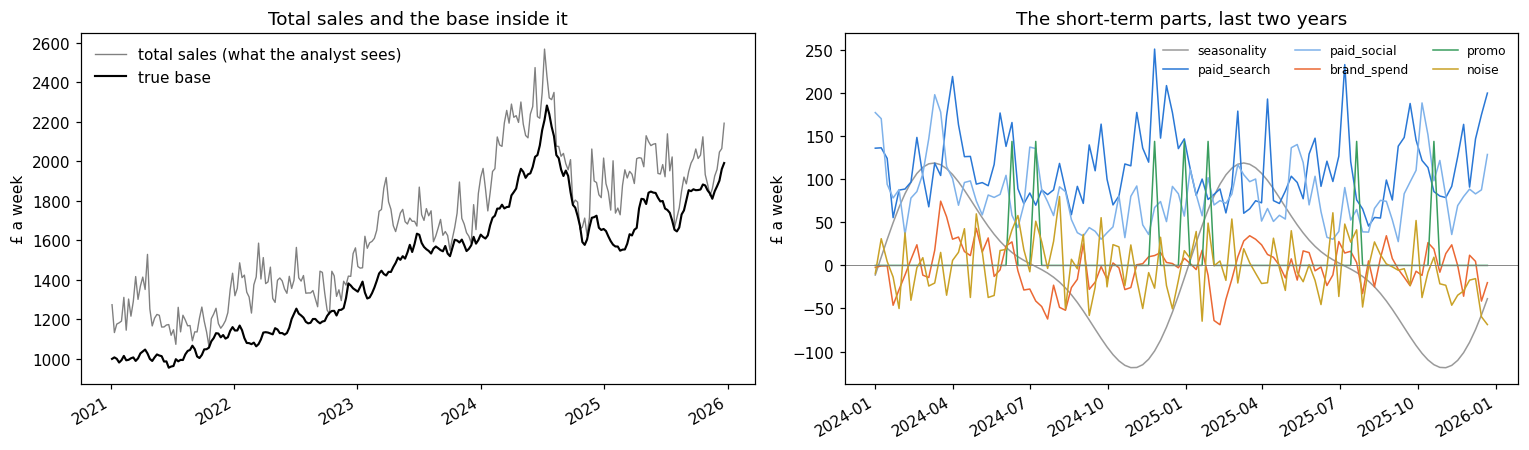

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
ax.plot(total.index, total, color="grey", lw=0.9, label="total sales (what the analyst sees)")
ax.plot(parts.index, parts["base"], color="black", lw=1.4, label="true base")
ax.set_ylabel("£ a week")
ax.set_title("Total sales and the base inside it")
ax.legend(frameon=False)
ax = axes[1]
window = parts.iloc[-104:]
for name, colour in [
    ("seasonality", "#9a9a9a"),
    ("paid_search", "#2a78d6"),
    ("paid_social", "#7fb2ea"),
    ("brand_spend", "#eb6834"),
    ("promo", "#3a9e5f"),
    ("noise", "#c9a227"),
]:
    ax.plot(window.index, window[name], color=colour, lw=1, label=name)
ax.axhline(0, color="grey", lw=0.6)
ax.set_title("The short-term parts, last two years")
ax.set_ylabel("£ a week")
ax.legend(frameon=False, ncol=3, fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

The base is 88% of sales. Paid search and paid social add about £185 a week between them and seasonality swings £120 either way. The noise is about £30 a week, which is as large as a typical weekly move in the base itself.

## 2. The UCM

The UCM is the recipe in the agent skill (`skills/bayesian-vecm/reference/base-sales.md`): a random-walk level with drift (`"lldtrend"`), two fixed annual harmonics and the four short-term drivers as regressors. It is fitted on total sales in £, because the parts add up in £.

In [5]:
PERIOD = 365.25 / 7.0

ucm = UnobservedComponents(
    total,
    level="lldtrend",  # random-walk level with drift, plus noise
    freq_seasonal=[{"period": PERIOD, "harmonics": 2}],
    stochastic_freq_seasonal=[False],  # fixed annual pattern
    exog=short_term,
).fit(disp=False, maxiter=1000)

The regression coefficients, in £ of sales per unit of each driver:

In [6]:
coef = ucm.params[[f"beta.{c}" for c in SHORT_TERM]]
true_coef = pd.Series(truth.sales_short_term["coef"])[SHORT_TERM]
pd.DataFrame({"truth": true_coef, "UCM": coef.to_numpy()}, index=SHORT_TERM).round(1)

,truth,UCM
brand_spend,86.4,80.5
paid_search,115.2,113.1
paid_social,72.0,67.3
promo,144.0,151.1


The two variances that split the weekly movement between the level and the noise:

In [7]:
ref = truth.sales_short_term["reference"]
true_level_sd = float(parts["base"].diff().std())
pd.DataFrame(
    {
        "truth": [NOISE * ref, true_level_sd],
        "UCM": [np.sqrt(ucm.params["sigma2.irregular"]), np.sqrt(ucm.params["sigma2.level"])],
    },
    index=["noise sd (£)", "weekly change in the level, sd (£)"],
).round(1)

,truth,UCM
noise sd (£),28.8,24.9
"weekly change in the level, sd (£)",29.0,40.5


**Reading the two tables.**

- **The coefficients are close.** Every short-term effect is within 7% of the truth, so the UCM gets the short-term part right. That is the easy case by design: the model is the truth's own form.
- **The noise is split roughly right but not exactly.** The UCM puts £25 of the £29 a week into noise and gives the level more weekly movement than it has (£41 against £29). On these data the level and the noise are hard to tell apart in five years.
- **With no noise at all the UCM's noise variance comes out at zero.** That is right, and it explains an earlier finding in the agent skill: on the default simulated data, which has no noise outside the brand system, the irregular always read zero.

## 3. Four candidate series

The smoothness check from the skill: the autocorrelation of weekly changes in log base, and their size. The true base reads about 0.3. A smoothed curve reads much higher. Noise that sits on top of a level pushes it below zero, because a high week tends to be followed by a lower one.

In [8]:
seasonal = ucm.freq_seasonal[0]["smoothed"]
bases = {
    "true_base": parts["base"],
    "ucm_minus": total - short_term.to_numpy() @ coef.to_numpy() - seasonal,
    "ucm_level": pd.Series(ucm.level["smoothed"], index=total.index),
    "ucm_keep_season": total - short_term.to_numpy() @ coef.to_numpy(),
    "total": total,
}


def smoothness(series):
    changes = np.log(series).diff().dropna()
    return changes.autocorr(), changes.std()


rows = {}
for arm, series in bases.items():
    ac, sd = smoothness(series)
    rows[LABELS[arm]] = {
        "change autocorrelation": ac,
        "change sd (%)": 100 * sd,
        "error vs true base, sd (£)": (
            series - parts["base"] - (parts["seasonality"] if arm == "ucm_keep_season" else 0)
        ).std()
        if arm != "total"
        else np.nan,
    }
pd.DataFrame(rows).T.round(2)

,change autocorrelation,change sd (%),"error vs true base, sd (£)"
true base,0.35,1.86,0.00
UCM: total minus contributions,-0.30,3.80,49.69
UCM: smoothed level,0.14,2.19,44.09
"UCM: minus contributions, seasonal kept",-0.26,3.87,31.64
"total sales, no base",-0.30,6.02,NaN


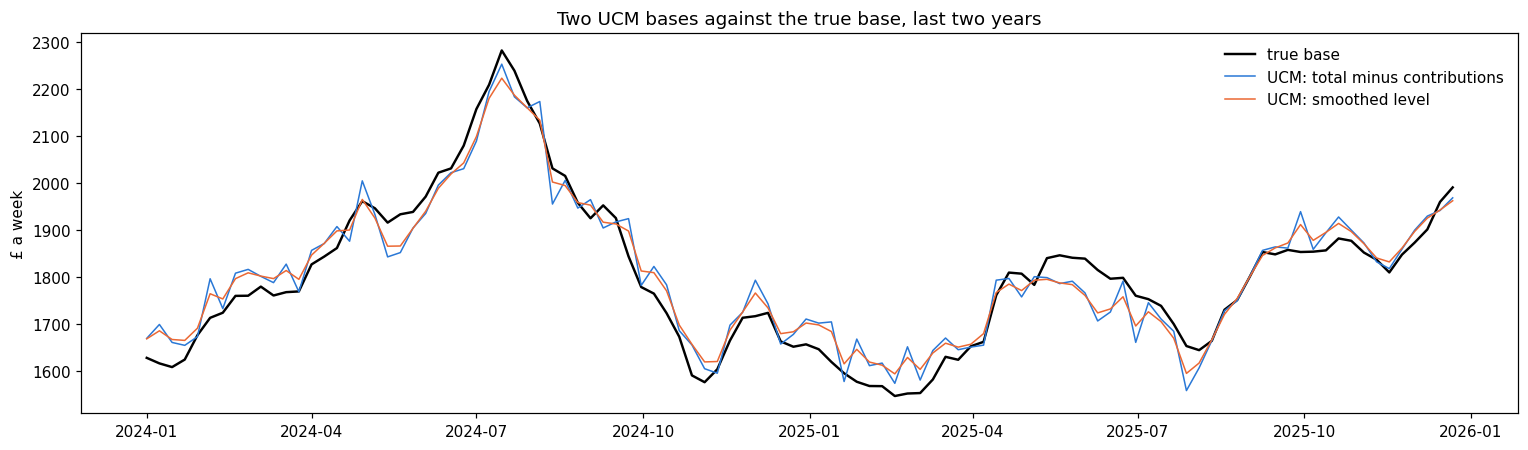

In [9]:
fig, ax = plt.subplots(figsize=(14, 4.2))
window = slice(-104, None)
for arm in ["true_base", "ucm_minus", "ucm_level"]:
    s = bases[arm].iloc[window]
    ax.plot(
        s.index, s, color=COLOURS[arm], lw=1.6 if arm == "true_base" else 1.0, label=LABELS[arm]
    )
ax.set_ylabel("£ a week")
ax.set_title("Two UCM bases against the true base, last two years")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Reading the table and chart.**

- **Total minus contributions keeps the noise.** Its weekly changes are twice as large as the true base's (3.8% against 1.9%) and negatively autocorrelated. That is the 2% noise sitting on top of the base.
- **The smoothed level takes most of the noise out.** Its changes are close in size to the true base's (2.2%). But it is a two-sided estimate: each week uses the weeks after it as well.
- **Both miss the true base by £30 to £50 a week in slow waves.** Most of that comes from the seasonal estimate. Over five years a random-walk level and an annual cycle are partly interchangeable, so the UCM's seasonal component picks up some of the level's slow swings, and the base inherits the error. Keeping the seasonality in the base (the purple arm) cuts the error to £32.

## 4. One VECM per base

The same model as the other guides: rank 2, one lag, `"co"`, the five brand drivers in levels. Two arms need more:

- **Seasonal kept:** the base still has the seasonal swing, so the harmonics enter the sales equation.
- **No base:** paid search, paid social, promo, brand spend's short-term hit and the harmonics move the *level* of sales for one week. The VECM models weekly growth, so they enter the sales equation as weekly changes, excluded from the brand metric equations.

Each fit takes about 30 seconds.

In [10]:
FIT = {
    "draws": DRAWS,
    "tune": TUNE,
    "chains": CHAINS,
    "target_accept": 0.9,
    "random_seed": 14,
    "progressbar": False,
}


def harmonics(index, n=2):
    angle = 2 * np.pi * np.arange(len(index)) / PERIOD
    cols = {}
    for h in range(1, n + 1):
        cols[f"sin{h}"] = np.sin(h * angle)
        cols[f"cos{h}"] = np.cos(h * angle)
    return pd.DataFrame(cols, index=index)


def fit_arm(arm):
    fit_endog = endog.copy()
    fit_endog[SALES] = np.log(bases[arm])
    fit_exog, kwargs = exog.copy(), {}
    if arm == "ucm_keep_season":
        # Seasonality stays in the base, so the VECM models it in the sales equation.
        changes = harmonics(total.index).diff()
        changes.columns = [f"d_{c}" for c in changes.columns]
        fit_exog = pd.concat([exog, changes], axis=1)
        kwargs["excluded"] = {AWARE: list(changes.columns), CONS: list(changes.columns)}
    if arm == "total":
        # Short-term drivers move the level of sales for one week, so they
        # enter the growth equation for sales as weekly changes.
        changes = pd.concat([short_term, harmonics(total.index)], axis=1).diff()
        changes.columns = [f"d_{c}" for c in changes.columns]
        fit_exog = pd.concat([exog, changes], axis=1)
        kwargs["excluded"] = {AWARE: list(changes.columns), CONS: list(changes.columns)}
    # Drop the first week so every fit uses the same weeks.
    return BayesianVECM(**SPEC, **kwargs).fit(fit_endog.iloc[1:], exog=fit_exog.iloc[1:], **FIT)


models = {}

In [11]:
models["true_base"] = fit_arm("true_base")

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B]


In [12]:
models["ucm_minus"] = fit_arm("ucm_minus")

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B]


In [13]:
models["ucm_keep_season"] = fit_arm("ucm_keep_season")

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B_raw]


In [14]:
models["ucm_level"] = fit_arm("ucm_level")

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B]


In [15]:
models["total"] = fit_arm("total")

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B_raw]


In [16]:
for arm, model in models.items():
    s = model.summary().apply(pd.to_numeric, errors="coerce")
    print(
        f"{LABELS[arm]:<32} divergences {int(model.idata_.sample_stats['diverging'].sum())}, "
        f"max r-hat {s['r_hat'].max():.3f}, min bulk ESS {s['ess_bulk'].min():.0f}"
    )

true base                        divergences 0, max r-hat 1.000, min bulk ESS 691


UCM: total minus contributions   divergences 0, max r-hat 1.000, min bulk ESS 1190


UCM: minus contributions, seasonal kept divergences 0, max r-hat 1.010, min bulk ESS 881


UCM: smoothed level              divergences 0, max r-hat 1.000, min bulk ESS 1282


total sales, no base             divergences 0, max r-hat 1.000, min bulk ESS 1163


## 5. What the business wants: the return on brand spend

The quantity a brand team plans with is how much one-off brand spend lifts sales **for good**. Here: the permanent lift in weekly sales from £1,000 of brand spend in one week, in £ a week. It is the log response at week 260 times average weekly sales over the last year of the series each model saw. The truth uses the true base.

In [17]:
HORIZON = 260


def true_response(steps):
    pi = truth.alpha @ truth.beta.T
    y, dy, out = np.zeros(3), np.zeros(3), []
    for h in range(steps + 1):
        dy = pi @ y + truth.gamma @ dy + (truth.b[:, 0] if h == 0 else 0.0)
        y = y + dy
        out.append(y[0])
    return np.array(out)


true_path = true_response(HORIZON)
true_level = float(parts["base"].iloc[-52:].mean())
lift_truth = true_path[-1] * true_level


def describe(x, fmt="{:,.0f}"):
    lo, hi = np.percentile(x, TAILS)
    return f"{fmt.format(np.median(x))} ({fmt.format(lo)} to {fmt.format(hi)})"


paths, rows = {}, {}
for arm, model in models.items():
    irf = model.exog_irf(HORIZON).sel(response_variable=SALES, exog_variable="brand_spend")
    irf = irf.stack(sample=("chain", "draw")).transpose("sample", ...).values
    level = float(bases[arm].iloc[-52:].mean())
    paths[arm] = irf * level
    post = model.idata_.posterior
    rows[LABELS[arm]] = {
        "permanent lift, £ a week": describe(paths[arm][:, -1]),
        "covers truth": bool(np.percentile(paths[arm][:, -1], TAILS[0]) <= lift_truth)
        & bool(lift_truth <= np.percentile(paths[arm][:, -1], TAILS[1])),
        "alpha (sales)": describe(post["alpha"].values[..., 0, 0].ravel(), "{:.2f}"),
        "sales shock sd (%)": describe(
            100 * np.sqrt(post["Sigma"].values[..., 0, 0].ravel()), "{:.2f}"
        ),
    }
print(
    f"Truth: permanent lift £{lift_truth:,.0f} a week, alpha {truth.alpha[0, 0]:.2f}, "
    f"sales shock sd {100 * np.sqrt(truth.sigma[0, 0]):.2f}%"
)
pd.DataFrame(rows).T

Truth: permanent lift £39 a week, alpha -0.24, sales shock sd 1.34%


,"permanent lift, £ a week",covers truth,alpha (sales),sales shock sd (%)
true base,44 (32 to 57),True,-0.23 (-0.30 to -0.17),1.34 (1.25 to 1.45)
UCM: total minus contributions,45 (34 to 57),True,-0.28 (-0.37 to -0.19),3.21 (2.96 to 3.47)
"UCM: minus contributions, seasonal kept",44 (34 to 55),True,-0.52 (-0.62 to -0.41),3.00 (2.80 to 3.25)
UCM: smoothed level,46 (35 to 59),True,-0.14 (-0.20 to -0.08),1.94 (1.81 to 2.09)
"total sales, no base",44 (33 to 55),True,-0.29 (-0.38 to -0.20),3.08 (2.86 to 3.32)


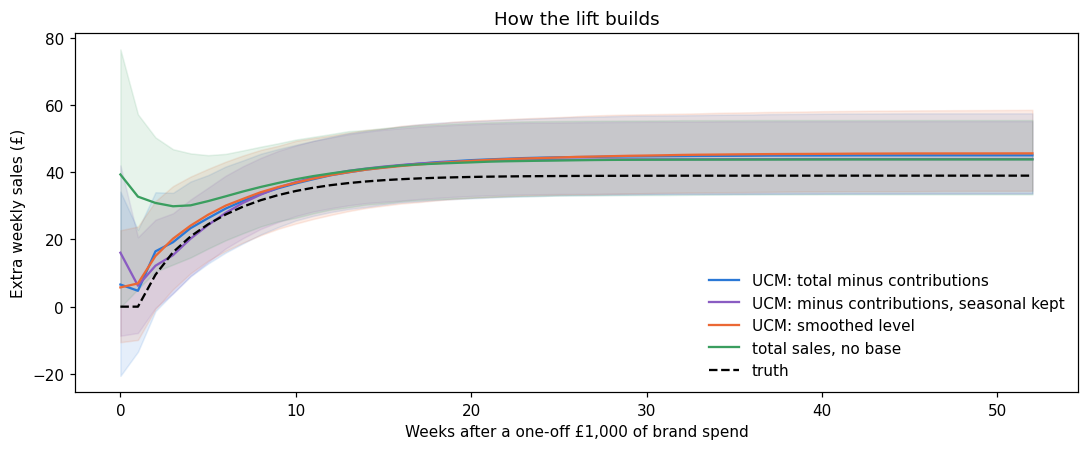

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.2))
weeks = np.arange(HORIZON + 1)
for arm in ["ucm_minus", "ucm_keep_season", "ucm_level", "total"]:
    lo, med, hi = np.percentile(paths[arm][:, :53], [TAILS[0], 50, TAILS[1]], axis=0)
    ax.fill_between(weeks[:53], lo, hi, color=COLOURS[arm], alpha=0.12)
    ax.plot(weeks[:53], med, color=COLOURS[arm], label=LABELS[arm])
ax.plot(weeks[:53], true_path[:53] * true_level, color="black", ls="--", label="truth")
ax.set_xlabel("Weeks after a one-off £1,000 of brand spend")
ax.set_ylabel("Extra weekly sales (£)")
ax.set_title("How the lift builds")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Reading the table and chart.**

- **Every arm gives the same return.** £44 to £46 a week for good, per £1,000 of brand spend, against a truth of £39. The fit on the true base says £44 too, so the gap is this data set's sampling error, not the base.
- **The short-run parts differ.** The noise in total minus contributions and in total sales lands in the sales shocks, which come out at 3% a week against a true 1.3%. The smoothed level's shocks are smaller but still too large, and its adjustment speed is too slow (-0.14 against -0.24).
- **The lift builds at the right pace** in all the UCM arms. Total sales starts high in week 0. Brand spend's same-week hit and the noise are hard to separate there, so read its first weeks with care.

## 6. Is one data set enough?

No. `tools/ucm_base_check.py` repeats sections 2 to 5 on 10 data sets at three noise levels: 0%, 2% and 5% of the reference level. That is 130 fits. The tables show the median error against the truth, the share of 90% intervals that contain it and the median interval width as a share of the truth.

In [19]:
runs = pd.read_csv(ROOT / "tools" / "ucm_base_check_results.csv")
ARM_ORDER = ["true_base", "ucm_minus", "ucm_keep_season", "ucm_level", "total"]
runs["arm"] = pd.Categorical(runs["arm"], ARM_ORDER, ordered=True)
runs = runs.sort_values(["noise", "arm"])
lift = runs[runs["quantity"] == "lift_permanent"].copy()
lift["error"] = lift["median"] / lift["truth"] - 1
lift["width"] = (lift["upper"] - lift["lower"]) / lift["truth"]
table = lift.groupby(["noise", "arm"], sort=False, observed=True).agg(
    error=("error", "median"),
    coverage=("covered", "mean"),
    width=("width", "median"),
    data_sets=("seed", "nunique"),
)
table["error"] = table["error"].map("{:+.0%}".format)
table["coverage"] = table["coverage"].map("{:.0%}".format)
table["width"] = table["width"].map("{:.0%}".format)
print("Permanent lift from a £1,000 brand spend pulse: median error, 90% coverage, interval width")
table

Permanent lift from a £1,000 brand spend pulse: median error, 90% coverage, interval width


error coverage width  data_sets
noise arm                                            
0.00  true_base         +0%     100%   49%         10
      ucm_minus         +3%     100%   55%         10
      ucm_keep_season   -1%     100%   47%         10
      ucm_level         +4%     100%   56%         10
      total             -6%     100%   56%         10
0.02  ucm_minus         +0%     100%   52%         10
      ucm_keep_season   -1%     100%   46%         10
      ucm_level         +2%     100%   53%         10
      total             -5%     100%   48%         10
0.05  ucm_minus         -2%      90%   46%         10
      ucm_keep_season   -1%     100%   45%         10
      ucm_level         -2%      90%   57%         10
      total             -6%      90%   46%         10

**The return on brand spend does not depend on the base.** Across 10 data sets and three noise levels every arm is within 6% of the truth. Coverage is 90% to 100% and the intervals are about as wide as the true base's. The long-run effect runs through the shared trend: whatever the base keeps or loses week to week, base sales and consideration still move together over the years, and the cointegration carries the return.

The same runs, for the short-run quantities: the lift at week 4 (how fast the effect builds), `alpha` for sales (how fast sales close the gap to consideration) and the size of the sales shocks. `change_autocorr` is the smoothness check. `false_direction` is the share of fits that find sales leading awareness or consideration, short run or long run, with evidence of 0.95 or more. The truth has no such link. `ucm_noise_zero` is the share of UCM fits whose noise variance came out at zero.

In [20]:
other = runs[runs["quantity"].isin(["alpha_sales", "sigma_sales", "lift_week4"])].copy()
other["error"] = other["median"] / other["truth"] - 1
t2 = other.pivot_table(
    index=["noise", "arm"], columns="quantity", values="error", aggfunc="median", observed=True
)
t2 = t2.reindex(table.index)
first = runs.drop_duplicates(["seed", "noise", "arm"]).copy()
evidence_cols = [c for c in runs.columns if c.startswith("evidence_sales_to")]
first["evidence_any"] = first[evidence_cols].max(axis=1)
extra = first.groupby(["noise", "arm"], sort=False, observed=True).agg(
    change_autocorr=("change_autocorr", "median"),
    false_direction=(
        "evidence_any",
        lambda e: (e >= 0.95).mean(),
    ),
    ucm_noise_zero=("ucm_irregular_sd", lambda s: (s < 1.0).mean() if s.notna().any() else np.nan),
)
out = pd.concat([t2.map("{:+.0%}".format), extra.reindex(table.index)], axis=1)
out["change_autocorr"] = out["change_autocorr"].round(2)
out["false_direction"] = out["false_direction"].map("{:.0%}".format)
out["ucm_noise_zero"] = out["ucm_noise_zero"].map(lambda v: "" if pd.isna(v) else f"{v:.0%}")
out

alpha_sales lift_week4 sigma_sales  change_autocorr false_direction ucm_noise_zero
noise arm                                                                                               
0.00  true_base               +8%        -6%         +1%             0.29             10%               
      ucm_minus              -24%       -28%         +3%             0.29             20%           100%
      ucm_keep_season        -18%        -6%         +3%             0.40             20%           100%
      ucm_level              -23%       -30%         +3%             0.29             20%           100%
      total                  -65%       +13%        +19%            -0.30             10%               
0.02  ucm_minus              +85%       -18%       +111%            -0.27             20%            10%
      ucm_keep_season        +95%        -1%       +108%            -0.20             20%            10%
      ucm_level              -13%       -28%        +24%             0.17             30%            10%
      total                   -7%       +22%       +111%            -0.31             10%               
0.05  ucm_minus             +230%        +3%       +331%            -0.45             20%             0%
      ucm_keep_season       +239%       +15%       +327%            -0.43             20%             0%
      ucm_level              -69%       -42%        -30%             0.53             70%             0%
      total                 +130%        +7%       +323%            -0.36             10%

**The short-run picture does depend on the base.**

- **Noise outside the brand system goes into the VECM.** With total minus contributions or total sales the sales shocks are twice too large at 2% noise and four times at 5%. `alpha` comes out much too fast (at 2% noise in the UCM arms, at 5% in all of them), because a noisy week looks like a gap that closes the week after. The return is still right because the noise does not move consideration.
- **Removing the UCM's seasonal estimate slows the effect.** At 0% and 2% noise the week-4 lift is 18% to 28% too low with total minus contributions. Keeping the seasonality in the base and putting the harmonics in the sales equation fixes it (-6% and -1%).
- **The smoothed level hides the noise and distorts the dynamics.** At 5% noise `alpha` is 69% too slow, the week-4 lift is 42% too low and 7 of 10 fits find sales leading a brand metric that it does not lead. The two-sided smoother lets future sales into this week's base, which is exactly what a direction test picks up. The other arms stay at 10% to 20%, close to the true base's 10%.
- **Total sales with no base** gets the return and the direction tests right, with the wider short-run errors of the noisy arms. It needs the short-term drivers entered as weekly changes, which is easy to get wrong.

## 7. What this means

- **For the return on brand spend, the base hardly matters.** A UCM base, the smoothed level or total sales all give it within a few percent, with honest intervals. Cointegration between sales and consideration carries the long-run effect, and a base built in any of these ways keeps it.
- **For anything short-run, the base matters a lot.** Adjustment speed, how fast the lift builds, the size of the sales shocks and the direction tests all move with the choice.
- **Best route so far:** total sales minus the UCM's regression contributions, with the seasonality kept in the base and the harmonics in the VECM's sales equation. It has the smallest base error and the best timing at 0% and 2% noise. Treat it as provisional: the checks below cover more settings, but not all the ways real seasonality differs from two smooth harmonics.
- **Do not read `alpha` or the shock size as brand facts** when sales have noise the brand system does not explain. They absorb that noise.
- **Avoid the smoothed level when the UCM finds real noise.** It gives the right return but the wrong dynamics, and its direction tests find links that are not there. When the UCM's noise variance is zero, the smoothed level and total minus contributions are the same series and the choice does not matter.

**Further checks.** Three scripts in `tools/` push on the findings. Each uses the same scoring as section 6.

- **Seasonality** (`seasonality_check.py`, 230 fits). Keeping the seasonality in gave the better week-4 lift in every setting tried except three years of data, where both routes are noisy:

  | Setting | Kept in the base | Seasonal estimate removed |
  |---|---|---|
  | UCM harmonics 1 / 2 / 3 (truth 2) | -10% / -1% / -1% | -22% / -18% / -16% |
  | 3 / 5 / 8 years of data | +8% / -1% / -1% | +7% / -18% / -6% |
  | Seasonal pattern drifting a little / a lot | 0% / -11% | -19% to -25% / -29% to -39% |

  The cost: with the seasonal swing still in the base the rank test (`select_coint_rank`, which has no seasonal terms) finds the true rank in only 2 of 10 data sets at five years. Run it on a deseasonalised copy. The return stays within 6% throughout.
- **Performance spend that follows demand** (`demand_feedback_check.py`, 100 fits). When search spend rose with consideration growth, the UCM's search coefficient came out 3% to 10% too high. The return moved by 1% or less and the base still cointegrated with consideration. Search here is 7% of sales; a larger channel would move more.
- **Carryover and saturation** (`mmm_trend_check.py`, 60 fits on 5 data sets). A Bayesian MMM (PyMC-Marketing) is needed for these. Its total minus contributions behaves like the UCM base here. Its time-varying intercept, used as the base, gets the return right but the short run badly wrong at every lengthscale tried: `alpha` about 93% too slow and false direction findings in 4 of 5 fits.

**Not covered yet.**

- **Brand metrics with seasonality of their own.** Here only sales are seasonal.
- **Seasonality that is not smooth:** Christmas, Black Friday and other spikes that a few harmonics cannot follow.